# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/notebooks/meeting19_trees_ensembles_attribution.ipynb)

# BME i9400 — Meeting 19
## Trees, Ensembles, and Attribution

**Fall 2026 · Wednesday, November 18**

Today's lecture is about decision trees and the two ways of combining many trees into one model:
random forests, which average trees grown independently, and gradient boosting, which grows trees
one after another to correct each other's errors. It compares both with logistic regression on the
clinical data of Meetings 8 to 12, and closes with two ways of asking which features a model relies
on: permutation importance and Shapley values.

> The Lab 2 defense quiz takes the first ten minutes of today's meeting.

**Agenda**

1. Decision trees
2. Choosing a split
3. The variance of a deep tree
4. Bagging and random forests
5. Gradient boosting
6. Ensembles on the clinical data
7. Which features matter: impurity and permutation importance
8. Shapley values
9. Connection to the course

---
## 1 — Decision trees

A **decision tree** predicts by asking a sequence of yes-or-no questions about single features:
"is glucose above 128 mg/dl?", then, depending on the answer, another question, until it reaches a
final answer.

- each question is a **split**: one feature compared with one threshold
- the questions are arranged as a tree: the first split is the **root**; each answer leads to a
  further split or to a **leaf**
- a leaf predicts the fraction of positive training samples that reached it

> The **depth** of a tree is the largest number of splits between the root and a leaf. A tree of
> depth $k$ has at most $2^k$ leaves.

The cell below fits trees of depth 1, 3, and 12 to the simulated "abnormal in either direction" data
of Meeting 17, section 1.

In [9]:
import itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

rng = np.random.default_rng(17)                                     # the data of Meeting 17
Xs  = rng.normal(size=(400, 2))
r   = np.sqrt((Xs[:, 0] / 1.2) ** 2 + (Xs[:, 1] / 0.9) ** 2)
ys  = (rng.random(400) < 1 / (1 + np.exp(-4 * (r - 1.3)))).astype(int)
Xs_tr, Xs_va, ys_tr, ys_va = train_test_split(Xs, ys, test_size=0.5, random_state=0, stratify=ys)

trees = {k: DecisionTreeClassifier(max_depth=k, random_state=0).fit(Xs_tr, ys_tr) for k in [1, 3, 12]}
for k, t in trees.items():
    print(f"depth {k:>2}: {t.get_n_leaves():>3} leaves   training accuracy {t.score(Xs_tr, ys_tr):.3f}   "
          f"validation accuracy {t.score(Xs_va, ys_va):.3f}")

depth  1:   2 leaves   training accuracy 0.705   validation accuracy 0.650
depth  3:   8 leaves   training accuracy 0.845   validation accuracy 0.765
depth 12:  36 leaves   training accuracy 0.995   validation accuracy 0.775


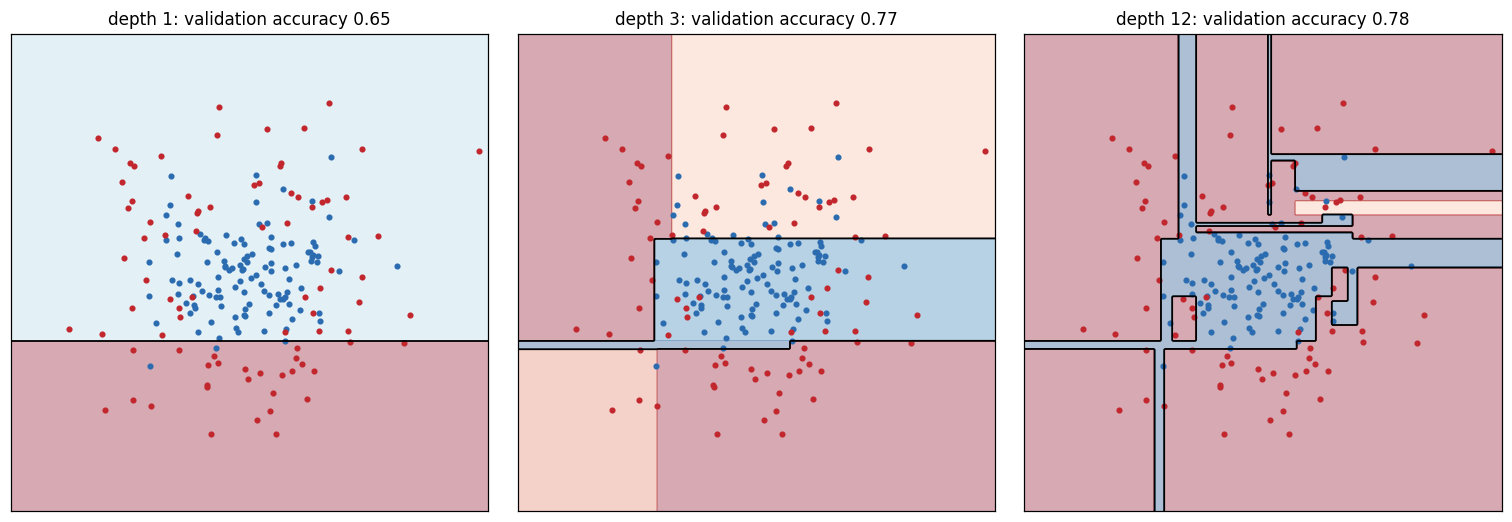

In [10]:
def boundary(ax, predict, title, X=Xs_tr, y=ys_tr, lim=3.6):
    g = np.linspace(-lim, lim, 300)
    A, B = np.meshgrid(g, g)
    P = predict(np.column_stack([A.ravel(), B.ravel()])).reshape(A.shape)
    ax.contourf(A, B, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.35)
    ax.contour(A, B, P, levels=[0.5], colors="k", linewidths=1.2)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=9, color="#2b6cb0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=9, color="#c1272d")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.7))
for ax, (k, t) in zip(axes, trees.items()):
    boundary(ax, lambda Z, t=t: t.predict_proba(Z)[:, 1],
             f"depth {k}: validation accuracy {t.score(Xs_va, ys_va):.2f}")
plt.tight_layout(); plt.show()

Every split compares one feature with a threshold, so every boundary is made of horizontal and
vertical segments: the tree approximates the ellipse with a staircase of rectangles. Depth 1 cuts the
plane once and underfits. Depth 3 encloses the centre. Depth 12 keeps splitting until almost every
leaf is pure: it classifies 99.5% of the training points correctly by drawing small boxes around
individual points, and gains almost nothing on validation data. The gap between training and
validation accuracy is the variance of Meeting 11, with depth in the role of capacity.

> Trees need no standardisation, because a split on "glucose > 128" is unchanged by any rescaling of
> glucose. They handle interactions naturally — a split on age below a split on glucose means the age
> effect differs by glucose level — and they can handle missing values and categorical features
> directly.

---
## 2 — Choosing a split

A tree is grown **greedily**, one split at a time: at each node, every feature and every threshold
is tried, and the split that makes the two resulting groups as pure as possible is kept. Purity is
measured by the **Gini impurity** of a group in which a fraction $p$ is positive:

$$G = 2p(1 - p)$$

> $G = 0$ when the group is pure ($p = 0$ or $p = 1$), and $G = 0.5$, its maximum, when $p = 0.5$.
> It is the probability that two samples drawn at random from the group, with replacement, have
> different labels.

A split sends $n_L$ samples left and $n_R$ right. Its quality is the weighted impurity of the two
children,

$$G_{\text{split}} = \frac{n_L}{n}\, G_L + \frac{n_R}{n}\, G_R$$

and the split with the smallest $G_{\text{split}}$ is chosen.

> "Greedy" means that each split is the best available at that moment, without looking ahead. Finding
> the best tree overall is computationally intractable, so no tree-growing algorithm attempts it.

The cell below loads the diabetes data, with every impossible zero marked as missing and then filled
with the median (Meeting 10), and finds the best single split on glucose by trying every threshold.

In [11]:
from sklearn.impute import SimpleImputer

pima = pd.read_csv("https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/diabetes.csv")
measured = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
pima[measured] = pima[measured].replace(0, np.nan)
X, y  = pima.drop(columns="Outcome"), pima["Outcome"].values
names = list(X.columns)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=9400)
imputer = SimpleImputer(strategy="median").fit(X_dev)
Xi_dev  = pd.DataFrame(imputer.transform(X_dev), columns=names)

gini = lambda p: 2 * p * (1 - p)
g = Xi_dev["Glucose"].values
candidates = np.unique(g)[:-1]
weighted = [np.mean(g <= c) * gini(y_dev[g <= c].mean()) + np.mean(g > c) * gini(y_dev[g > c].mean()) for c in candidates]
best = candidates[np.argmin(weighted)]
print(f"impurity before splitting: {gini(y_dev.mean()):.3f}")
print(f"best split on glucose: glucose <= {best:.0f} mg/dl, weighted impurity {min(weighted):.3f}")

impurity before splitting: 0.454
best split on glucose: glucose <= 127 mg/dl, weighted impurity 0.372


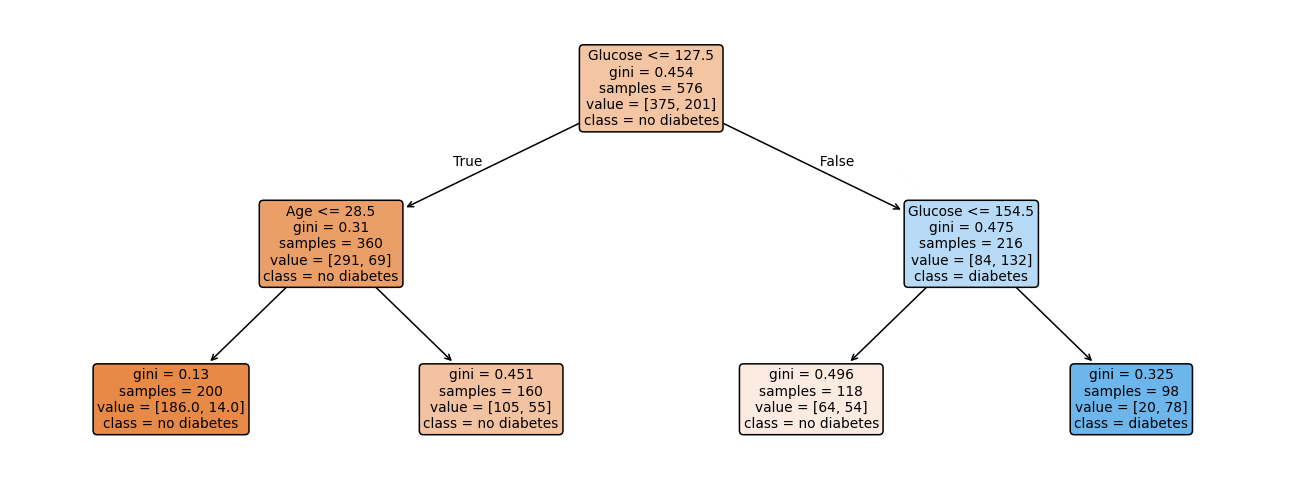

In [12]:
stump = DecisionTreeClassifier(max_depth=2, random_state=0).fit(Xi_dev, y_dev)
fig, ax = plt.subplots(figsize=(12, 4.6))
plot_tree(stump, feature_names=names, class_names=["no diabetes", "diabetes"], filled=True,
          impurity=True, proportion=False, rounded=True, fontsize=9, ax=ax)
plt.tight_layout(); plt.show()

scikit-learn's root split is the one found by hand above: among all eight measurements and all
thresholds, glucose separates the women best. The second level splits the lower-glucose group on
age, and the higher-glucose group on glucose again, at a higher threshold. A tree of depth 2 is a set of four rules that a clinician can read and check; this
interpretability is the main reason single trees are still used in clinical decision rules.

---
## 3 — The variance of a deep tree

A deep tree fits its training data closely, so a small change in the data can change its early
splits, and every split beneath them changes too. The cell below grows full-depth trees on three
**bootstrap samples** of the development set and prints their first two levels.

> A **bootstrap sample** is a sample of $n$ rows drawn **with replacement** from the $n$ rows of the
> data: some rows appear twice or more, and about 37% do not appear at all (Meeting 20 uses bootstrap
> samples to put confidence intervals on results).

In [5]:
def first_splits(t):
    tr = t.tree_
    root, left, right = 0, tr.children_left[0], tr.children_right[0]
    show = lambda n: f"{names[tr.feature[n]]} <= {tr.threshold[n]:.1f}" if tr.feature[n] >= 0 else "leaf"
    return f"root: {show(root):<24} left: {show(left):<26} right: {show(right)}"

boot = np.random.default_rng(0)
for b in range(3):
    idx = boot.integers(0, len(y_dev), len(y_dev))
    t = DecisionTreeClassifier(random_state=0).fit(Xi_dev.iloc[idx], y_dev[idx])
    print(f"bootstrap sample {b + 1}: depth {t.get_depth():>2}, {t.get_n_leaves():>3} leaves   {first_splits(t)}")

folds = StratifiedKFold(5, shuffle=True, random_state=9400)
for depth in [3, None]:
    s = cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=0), Xi_dev, y_dev, cv=folds, scoring="roc_auc")
    print(f"tree of depth {str(depth or 'unlimited'):>9}: 5-fold CV AUC {s.mean():.3f}")

bootstrap sample 1: depth 11,  65 leaves   root: Glucose <= 127.5         left: Pregnancies <= 4.5         right: BMI <= 28.8
bootstrap sample 2: depth 13,  69 leaves   root: Glucose <= 154.5         left: BMI <= 31.1                right: BMI <= 29.1
bootstrap sample 3: depth 13,  64 leaves   root: Glucose <= 154.5         left: Age <= 28.5                right: BMI <= 23.1
tree of depth         3: 5-fold CV AUC 0.753
tree of depth unlimited: 5-fold CV AUC 0.672


Every tree splits first on glucose, but the threshold moves from 127.5 to 154.5 mg/dl and the splits
beneath it change from sample to sample; the full trees have 64 to 69 leaves each. The unlimited tree's cross-validated
AUC is far below that of a tree of depth 3: it has low bias and very high variance. Limiting the
depth reduces the variance at the cost of bias. The ensembles of the next two sections reduce the
variance without limiting the depth.

---
## 4 — Bagging and random forests

Averaging reduces variance. If $B$ predictions each have variance $\sigma^2$ and every pair has
correlation $\rho$, their average has variance

$$\operatorname{Var}\!\left(\frac{1}{B}\sum_{b=1}^{B} f_b\right) = \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2$$

> The second term vanishes as $B$ grows; the first does not. Averaging many trees helps only as much
> as the trees differ from one another.

Two ideas make the trees differ:

- **Bagging** (bootstrap aggregating; Breiman, 1996): grow each tree on its own bootstrap sample,
  and average their predicted probabilities
- **Random forests** (Breiman, *Machine Learning*, 2001): in addition, at every split consider only
  a random subset of the features — by default $\sqrt{d}$ of them for classification — so that one
  strong feature such as glucose does not dominate the root of every tree, which lowers $\rho$

> Each tree never saw about 37% of the rows: its **out-of-bag** rows. Predicting each row with only the
> trees that did not see it gives an estimate of performance on new data without a separate
> validation set, from a single fit. `RandomForestClassifier(oob_score=True)` computes it.

The cell below grows forests of increasing size on the development set and records the out-of-bag
AUC.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

import warnings
warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")   # very small forests leave some rows unscored
sizes, oob_auc = [5, 10, 25, 50, 100, 200, 500], []
for B in sizes:
    forest = RandomForestClassifier(n_estimators=B, oob_score=True, random_state=0, n_jobs=-1).fit(Xi_dev, y_dev)
    oob_auc.append(roc_auc_score(y_dev, np.nan_to_num(forest.oob_decision_function_[:, 1], nan=0.5)))
print("trees:          ", sizes)
print("out-of-bag AUC: ", np.round(oob_auc, 3))

ring_forest = RandomForestClassifier(n_estimators=500, random_state=0).fit(Xs_tr, ys_tr)

trees:           [5, 10, 25, 50, 100, 200, 500]
out-of-bag AUC:  [0.67  0.702 0.785 0.807 0.818 0.82  0.825]


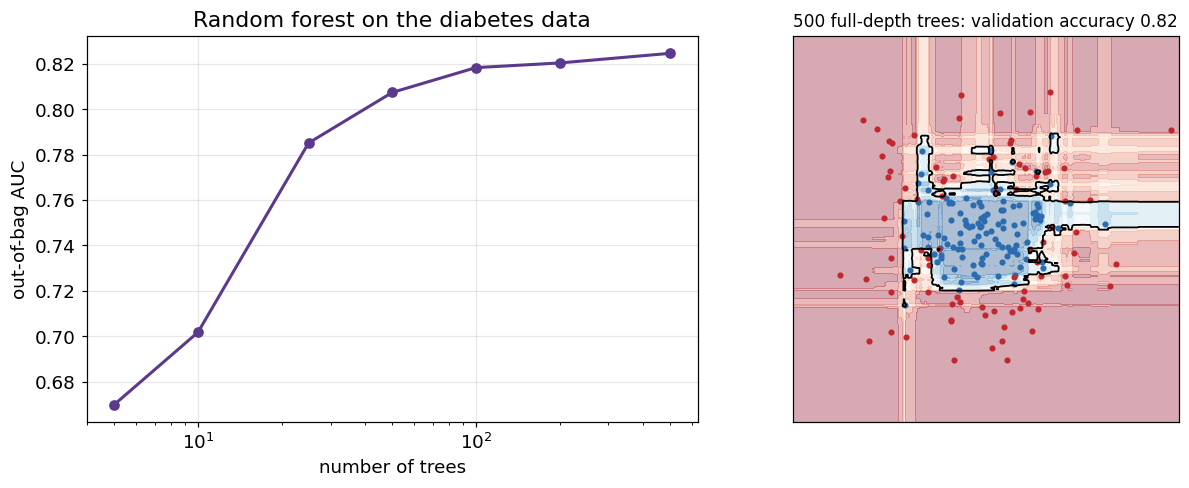

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].semilogx(sizes, oob_auc, "o-", color="#5b3a8e", lw=2)
axes[0].set_xlabel("number of trees"); axes[0].set_ylabel("out-of-bag AUC"); axes[0].grid(alpha=0.3)
axes[0].set_title("Random forest on the diabetes data")
boundary(axes[1], lambda Z: ring_forest.predict_proba(Z)[:, 1],
         f"500 full-depth trees: validation accuracy {ring_forest.score(Xs_va, ys_va):.2f}")
plt.tight_layout(); plt.show()

The out-of-bag AUC rises steeply over the first few dozen trees and then levels off: adding trees
never causes overfitting, it only stops helping once the second term of the variance formula is
small. On the simulated data, 500 full-depth trees — each of which overfits on its own — average to a
smooth boundary close to the ellipse.

> The number of trees is therefore not a hyperparameter to tune: use enough, typically a few hundred.
> The hyperparameters that matter are the number of features tried at each split (`max_features`) and
> the minimum size of a leaf (`min_samples_leaf`).

---
## 5 — Gradient boosting

**Boosting** builds the ensemble sequentially. It starts from a constant prediction and adds small
trees one at a time, each fitted to the errors that remain:

$$F_m(x) = F_{m-1}(x) + \nu\, h_m(x)$$

- $F_{m-1}$: the ensemble after $m - 1$ trees
- $h_m$: a small tree (depth 2 to 6) fitted to the **residuals** $y_i - F_{m-1}(x_i)$ of the current
  ensemble
- $\nu$: the **learning rate**, between 0 and 1, which shrinks each tree's contribution

> For squared error, the residual $y - F$ is the negative gradient of the loss with respect to the
> prediction $F$. For cross-entropy, the negative gradient with respect to the log-odds is $y - p$, the
> same error signal $\delta$ as in Meetings 8 and 17. Fitting each tree to the negative gradient is
> gradient descent in the space of functions, which gives **gradient boosting** its name (Friedman,
> *Annals of Statistics*, 2001).

The cell below runs gradient boosting by hand on a one-dimensional regression problem: 100 noisy
samples of a smooth curve, trees of depth 2, $\nu = 0.1$.

In [8]:
g1 = np.random.default_rng(5)
x1 = np.sort(g1.uniform(0, 10, 100))
y1 = np.sin(x1) + 0.3 * x1 + g1.normal(0, 0.35, 100)
grid = np.linspace(0, 10, 400)

nu, F, F_grid, stages = 0.1, np.full(100, y1.mean()), np.full(400, y1.mean()), {}
for m in range(1, 301):
    h = DecisionTreeRegressor(max_depth=2).fit(x1[:, None], y1 - F)       # fit the residuals
    F, F_grid = F + nu * h.predict(x1[:, None]), F_grid + nu * h.predict(grid[:, None])
    if m in (1, 10, 50, 300):
        stages[m] = (F_grid.copy(), np.sqrt(np.mean((y1 - F) ** 2)))
for m, (_, rmse) in stages.items():
    print(f"after {m:>3} trees: training RMSE {rmse:.3f}")

after   1 trees: training RMSE 1.072
after  10 trees: training RMSE 0.577
after  50 trees: training RMSE 0.303
after 300 trees: training RMSE 0.113


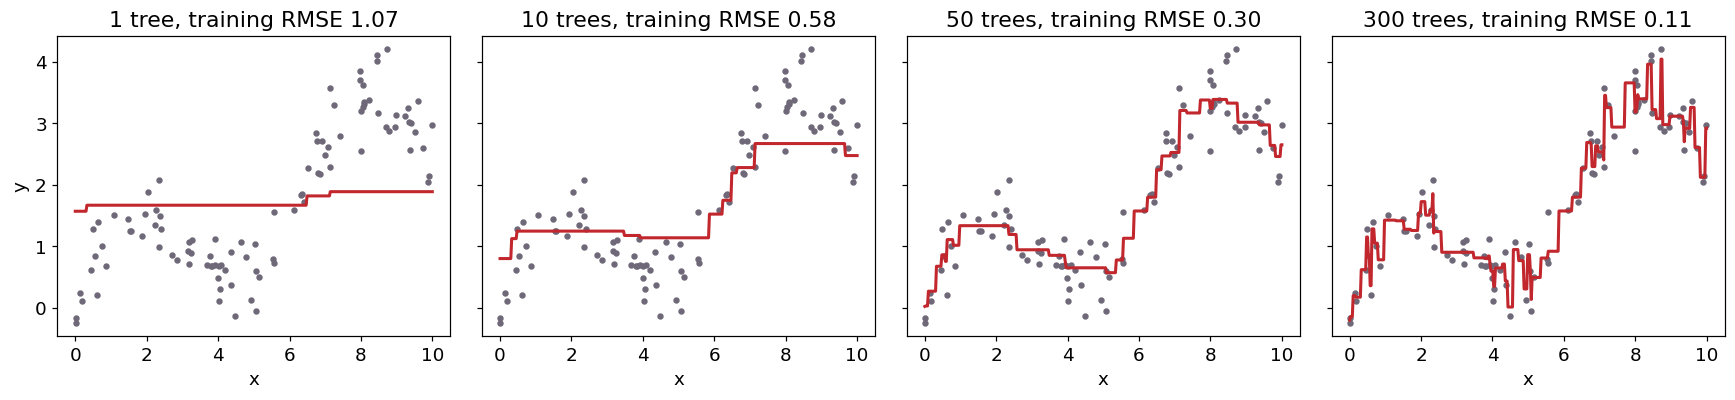

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (m, (Fg, rmse)) in zip(axes, stages.items()):
    ax.scatter(x1, y1, s=10, color="#6e6878")
    ax.plot(grid, Fg, color="#c1272d", lw=2)
    ax.set_title(f"{m} tree{'s' if m > 1 else ''}, training RMSE {rmse:.2f}"); ax.set_xlabel("x")
axes[0].set_ylabel("y"); plt.tight_layout(); plt.show()

After one tree the fit is a coarse step function shrunk toward the mean. Each further tree corrects
part of what remains, and by 50 trees the ensemble follows the curve. By 300 trees it has begun to
follow the noise: the training error keeps falling, and unlike a random forest, boosting **can**
overfit as trees are added.

> The number of trees and the learning rate trade off: a smaller $\nu$ needs more trees and usually
> generalises better. The number of trees is chosen by early stopping on validation data, as for the
> networks of Meeting 18. `HistGradientBoostingClassifier` in scikit-learn, and the libraries XGBoost
> and LightGBM, implement gradient boosting efficiently, with early stopping and native handling of
> missing values.

---
## 6 — Ensembles on the clinical data

The cell below compares six models on the development set by 5-fold cross-validated AUC, on the
folds of section 3:

- logistic regression (impute, standardise, fit), the model of Meetings 8 to 12
- single trees of depth 3 and of unlimited depth
- a random forest of 500 trees, with leaves of at least 5 women
- gradient boosting with scikit-learn's default settings, and with a smaller learning rate, shallower
  trees, and fewer of them

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

imp = lambda: SimpleImputer(strategy="median")
candidates = {
    "logistic regression":           make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=1000)),
    "tree, depth 3":                 make_pipeline(imp(), DecisionTreeClassifier(max_depth=3, random_state=0)),
    "tree, unlimited depth":         make_pipeline(imp(), DecisionTreeClassifier(random_state=0)),
    "random forest":                 make_pipeline(imp(), RandomForestClassifier(500, min_samples_leaf=5, random_state=0, n_jobs=-1)),
    "gradient boosting, default":    HistGradientBoostingClassifier(random_state=0),
    "gradient boosting, slow":       HistGradientBoostingClassifier(learning_rate=0.03, max_iter=200, max_depth=3, random_state=0),
}
for name, model in candidates.items():
    s = cross_val_score(model, X_dev, y_dev, cv=folds, scoring="roc_auc")
    print(f"{name:<30} 5-fold CV AUC {s.mean():.3f}   (SE {s.std(ddof=1) / np.sqrt(5):.3f})")

logistic regression            5-fold CV AUC 0.833   (SE 0.009)
tree, depth 3                  5-fold CV AUC 0.753   (SE 0.026)
tree, unlimited depth          5-fold CV AUC 0.663   (SE 0.017)
random forest                  5-fold CV AUC 0.835   (SE 0.015)
gradient boosting, default     5-fold CV AUC 0.809   (SE 0.015)
gradient boosting, slow        5-fold CV AUC 0.834   (SE 0.019)


Logistic regression, the random forest, and the slower gradient boosting are within a few
thousandths of each other, far less than one standard error. Gradient boosting with its default
settings — 100 trees of up to 31 leaves each at a learning rate of 0.1 — is worse; with a smaller
learning rate and shallower trees it matches the other two. A single
deep tree is far behind, as section 3 predicted.

> Gradient-boosted trees are the strongest general-purpose models for tabular data with many samples
> and many features, and they usually beat neural networks there (Grinsztajn et al., 2022). With eight
> measurements whose effects on the log-odds are close to linear, and about 600 women, there is little
> nonlinearity for them to find. The "slow" settings are the best of two tried, so their score is
> slightly optimistic (Meeting 12).

---
## 7 — Which features matter: impurity and permutation importance

A forest of 500 trees has no coefficients to read. Two measures summarise how much it relies on each
feature:

- **impurity importance** (`feature_importances_`): the total decrease in Gini impurity produced by
  splits on that feature, summed over all trees and normalised to sum to 1. It is computed from the
  training data during fitting.
- **permutation importance**: on held-out data, shuffle one feature's column, breaking its link with
  the outcome, and measure how much the AUC drops. Repeat for each feature.

> Permutation importance asks "how much worse are the predictions on new data without this feature's
> information?". Impurity importance asks "how often, and how usefully on the training data, did the
> trees split on this feature?".

To compare them, the cell below adds a ninth column of pure random noise, unrelated to diabetes, fits
a forest on the development set, and computes both measures — permutation importance on the test set.

In [15]:
from sklearn.inspection import permutation_importance

noise = np.random.default_rng(0)
Xn_dev, Xn_test = X_dev.assign(noise=noise.normal(size=len(X_dev))), X_test.assign(noise=noise.normal(size=len(X_test)))
forest = make_pipeline(imp(), RandomForestClassifier(500, random_state=0, n_jobs=-1)).fit(Xn_dev, y_dev)

impurity = pd.Series(forest[-1].feature_importances_, index=Xn_dev.columns)
perm = permutation_importance(forest, Xn_test, y_test, scoring="roc_auc", n_repeats=20, random_state=0)
permutation = pd.Series(perm.importances_mean, index=Xn_dev.columns)
table = pd.DataFrame({"impurity importance": impurity, "permutation importance (drop in test AUC)": permutation})
print(table.sort_values("impurity importance", ascending=False).round(3).to_string())

                          impurity importance  permutation importance (drop in test AUC)
Glucose                                 0.253                                      0.128
BMI                                     0.146                                      0.040
Age                                     0.136                                      0.026
DiabetesPedigreeFunction                0.106                                      0.010
noise                                   0.092                                      0.002
Pregnancies                             0.073                                      0.009
Insulin                                 0.070                                      0.010
BloodPressure                           0.066                                      0.001
SkinThickness                           0.059                                      0.001


Both measures rank glucose first, then BMI and age. They disagree about the noise column: impurity
importance ranks it above four real measurements, while its permutation importance is essentially
zero. Blood pressure and skin thickness also have near-zero permutation importance: the forest obtains
their information from the correlated BMI and glucose.

Full-depth trees split on the noise column deep in the tree, where few women remain, to separate the
last few training samples — and each such split reduces training impurity. Impurity importance counts
those reductions. A continuous feature offers the most thresholds and is favoured most (Strobl et al.,
*BMC Bioinformatics*, 2007).

> Report permutation importance computed on held-out data. Two cautions apply to both measures: when
> two features are strongly correlated, shuffling one leaves its information available through the
> other, so both can appear unimportant; and importance describes the model, not the biology — a
> feature can be important to the model without causing the outcome.

---
## 8 — Shapley values

Permutation importance describes the model over a whole dataset. A clinician looking at one patient's
prediction asks a different question: **why is this woman's predicted risk 0.69 rather than the
average 0.35?** Shapley values divide the difference between one prediction and the average
prediction among the features.

The idea comes from cooperative game theory (Shapley, 1953): the features are players who together
produce the prediction. For a set $S$ of features, let $v(S)$ be the average prediction when the
features in $S$ are fixed at this patient's values and the others are filled in from a background
sample of real patients. The Shapley value of feature $j$ is its added value $v(S \cup \{j\}) - v(S)$,
averaged over every set $S$ of the other features, with weights:

$$\phi_j = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(d - |S| - 1)!}{d!}\,\Big[v(S \cup \{j\}) - v(S)\Big]$$

> $F$ is the set of all $d$ features and $|S|$ is the number of features in $S$. The weights make
> $\phi_j$ the average of feature $j$'s added value over every order in which the features could be
> added one by one.
>
> The Shapley values add up exactly: $\phi_1 + \dots + \phi_d = f(x) - v(\varnothing)$, the patient's
> prediction minus the average prediction. This **additivity** is what makes them an explanation of
> that one prediction.

With $d = 8$ there are $2^8 = 256$ sets, few enough to compute $\phi$ exactly. The cell below does so
for one test patient, with the forest of section 6 refitted on the eight real measurements and 100
development patients as the background.

In [ ]:
rf = make_pipeline(imp(), RandomForestClassifier(500, min_samples_leaf=5, random_state=0, n_jobs=-1)).fit(X_dev, y_dev)
background = X_dev.sample(100, random_state=0).values
patient = X_test.iloc[[int(np.argsort(rf.predict_proba(X_test)[:, 1])[-20])]]       # a high-risk test patient
x, d = patient.values[0], len(names)

def v(S):
    # average prediction with the features in S fixed at the patient's values, the others from the background
    Z = background.copy(); Z[:, list(S)] = x[list(S)]
    return rf.predict_proba(pd.DataFrame(Z, columns=names))[:, 1].mean()

value = {S: v(S) for k in range(d + 1) for S in itertools.combinations(range(d), k)}
phi = np.zeros(d)
for j in range(d):
    for S, vS in value.items():
        if j not in S:
            w = math.factorial(len(S)) * math.factorial(d - len(S) - 1) / math.factorial(d)
            phi[j] += w * (value[tuple(sorted(S + (j,)))] - vS)

f_x, base = rf.predict_proba(patient)[0, 1], value[()]
print(patient.to_string(index=False))
print(f"\nprediction {f_x:.3f}   average prediction {base:.3f}   difference {f_x - base:+.3f}   sum of Shapley values {phi.sum():+.3f}")

In [ ]:
order = np.argsort(np.abs(phi))
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.barh([f"{names[j]} = {x[j]:g}" for j in order], phi[order],
        color=["#c1272d" if phi[j] > 0 else "#2b6cb0" for j in order])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Shapley value (change in predicted probability)")
ax.set_title(f"Why this patient's predicted risk is {f_x:.2f}, not {base:.2f}")
ax.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()

The Shapley values sum to the difference between this patient's prediction and the average, as they
must. Features in red raise her predicted risk and features in blue lower it, in units of probability.

> Computing $v(S)$ for every set takes $2^d$ evaluations, which is infeasible beyond about 20
> features. The `shap` library (Lundberg and Lee, *NeurIPS*, 2017) computes Shapley values for tree
> ensembles exactly and quickly (`shap.TreeExplainer`), and approximately for any model. Its plots are
> the standard way of reporting per-patient explanations, and in the capstone a summary of Shapley
> values over the test set is one acceptable form of error analysis.
>
> A Shapley value describes how the model uses a feature for this patient. It does not say that
> changing the feature would change her risk; that is a causal question, which the model cannot
> answer.

---
## 9 — Connection to the course

**Trees and the bias–variance trade-off.** Depth is capacity (Meeting 11). A random forest lowers
variance by averaging decorrelated deep trees; gradient boosting lowers bias by adding shallow trees,
one gradient step at a time (Meeting 13), and is regularised by its learning rate and by early
stopping (Meeting 18).

**The comparison.** On the diabetes data, logistic regression, a random forest, and tuned gradient
boosting are close. Whether a difference of one or two hundredths of AUC between two models is real is
the question of Meeting 20, which answers it with bootstrap confidence intervals for a paired
comparison.

**Attribution.** Permutation importance on held-out data summarises a whole model; Shapley values
explain one prediction. Both describe the model, not the disease.

## What to take away

- A decision tree is a sequence of single-feature splits, grown greedily by minimising the weighted
  Gini impurity of the children
- Deep trees have low bias and high variance; small changes in the data change the tree
- Random forests average deep trees grown on bootstrap samples with random feature subsets; more trees
  never overfit, and the out-of-bag estimate comes free
- Gradient boosting adds shallow trees fitted to the residuals (the negative gradient); it can overfit,
  so the number of trees is chosen by early stopping
- Impurity importance is biased toward continuous and noisy features; report permutation importance
  on held-out data
- Shapley values divide one prediction's departure from the average among the features, and add up
  exactly; they describe the model, not causes

### Monday, November 23 — Studio

Is the difference real? Bootstrap confidence intervals for a model's performance, and for the
difference between two models evaluated on the same patients. The capstone dataset choice and
analysis plan are due at the start of that meeting.

## Recommended resources

Everything here is optional and freely available unless marked **(CCNY)**. Each item covers material
from this lecture in a different style or voice; none of it is assigned.

### Start here

| Resource | Why this one | Time |
|---|---|---|
| **[Decision and Classification Trees, Clearly Explained](https://www.youtube.com/watch?v=_L39rN6gz7Y)** — StatQuest | Gini impurity and growing a tree, step by step. | 18 min |
| **[Random Forests Part 1](https://www.youtube.com/watch?v=J4Wdy0Wc_xQ)** — StatQuest | Bootstrap samples, random feature subsets, out-of-bag error. | 10 min |
| **[Gradient Boost Part 1: Regression Main Ideas](https://www.youtube.com/watch?v=3CC4N4z3GJc)** — StatQuest | Section 5's fitting of trees to residuals, drawn. | 16 min |

### Going further

| Resource | Why this one | Time |
|---|---|---|
| **[An Introduction to Statistical Learning](https://www.statlearning.com/)** — James, Witten, Hastie, Tibshirani, chapter 8 | Trees, bagging, random forests, and boosting at the level of this course. Free PDF. | 2 h |
| **[Interpretable Machine Learning](https://christophm.github.io/interpretable-ml-book/)** — Molnar, chapters on permutation importance and Shapley values | The clearest treatment of sections 7 and 8, with their pitfalls. Free online. | 1.5 h |
| **[Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html)** — scikit-learn user guide | Includes the impurity-versus-permutation comparison of section 7 on another dataset. | 20 min |
| **[Random Forests](https://doi.org/10.1023/A:1010933404324)** — Breiman, *Machine Learning*, 2001 | The original paper, including the out-of-bag estimate. | 1 h |
| **[Bias in random forest variable importance measures](https://doi.org/10.1186/1471-2105-8-25)** — Strobl et al., *BMC Bioinformatics*, 2007 | Why impurity importance favours continuous and noisy features. Open access. | 45 min |
| **[A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874)** — Lundberg and Lee, *NeurIPS*, 2017 | The SHAP paper. | 1 h |